# Exercise 1 - Linear Regression Task
# Created by: Sean Matthew Rosales Parabuac (ID: 639264)

# Loading Libraries & Connecting With Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Note that these last two are for features called Feature Scaling and Categorical Encoding
#This is needed and explained in its specific section later on
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

data = pd.read_csv("/kaggle/input/datasets/seanparabuac/king-county-house-price-regression/kc_house_data.csv")
data.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [2]:
data.tail()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287
21612,1523300157,20141015T000000,325000.0,2,0.75,1020,1076,2.0,0,0,...,7,1020,0,2008,0,98144,47.5941,-122.299,1020,1357


In [3]:
data.shape

(21613, 21)

In [4]:
data.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [6]:
#Checking for missing values just in case
print("Missing Values:")
print(data.isnull().sum())

#Checking for duplicate records
print("\nDuplicate Records:")
print(data.duplicated().sum())

data.isna().sum()

#Note that I only did this purely for the possibility that it may make the dataset more validated

Missing Values:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

Duplicate Records:
0


id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

# Data Preprocessing & Separation

In [7]:
#As there are certain columns that do not fit Linear Regression like ID and date, I deliberately left them out
X = data[["bedrooms","bathrooms","sqft_living","sqft_lot","floors","waterfront","view","condition","grade",
    "sqft_above","sqft_basement","yr_built","yr_renovated","zipcode","lat","long","sqft_living15","sqft_lot15"]]

#This is the target variable of house prices
y = data["price"]

#Double checking their number of rows and columns
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

X

Features Shape: (21613, 18)
Target Shape: (21613,)


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


In [8]:
#Identifying categorical features. This is ONLY here because the zipcode exists
categoricalFeatures = ["zipcode"]

#Separating the numerical features
numericalFeatures = [
    column for column in X.columns
    if column not in categoricalFeatures]

#Checking if they've been separated correctly.
print("Numerical Features:")
print(numericalFeatures)

print("\nCategorical Features:")
print(categoricalFeatures)

Numerical Features:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Categorical Features:
['zipcode']


In [9]:
#Splitting the data into an 80:20 scale for training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
) #Since everything will use the same scaling/sampling method, the code has been simplified
#This was suggested by ChatGPT to avoid clutter and usage of more lines

#Checking if the 80:20 ratio was actually followed
print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 17290
Testing Records: 4323


# Feature Scaling & Categorical Encoding
Because there are so many features within the dataset I chose, the code below utilizes feature scaling and categorical encoding, while hot-encoding the zip code column from the dataset. **This utility was suggested by ChatGPT.**

The reason for feature scaling is because of the huge difference in metrics between certain features. Some features have triple digit metrics, others only have single digit. Categorical encoding is used to handle the single category type feature, **The Zipcode**

In [10]:
#Creating a preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numericalFeatures),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categoricalFeatures)
    ]
)

# Model Training & Testing

In [11]:
#Fit preprocessing on training data
X_trainProcessed = preprocessor.fit_transform(X_train)

#Applying the preprocessing to test data
X_testProcessed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_trainProcessed.shape)
print("Processed Testing Shape:", X_testProcessed.shape)

Processed Training Shape: (17290, 87)
Processed Testing Shape: (4323, 87)


In [12]:
model = LinearRegression()

model.fit(X_trainProcessed, y_train)
#This will confirm if it worked
print("Linear Regression model trained successfully")

Linear Regression model trained successfully


In [13]:
#Creating predictions using preprocessed data
trainPredictions = model.predict(X_trainProcessed)
testPredictions = model.predict(X_testProcessed)

print("Predictions generated successfully")

Predictions generated successfully


In [14]:
#Calculating the MAE and MSE performance
trainMAE = mean_absolute_error(y_train, trainPredictions)
trainMSE = mean_squared_error(y_train, trainPredictions)
trainR2 = r2_score(y_train, trainPredictions)

#Same calculations for the testing data
testMAE = mean_absolute_error(y_test, testPredictions)
testMSE = mean_squared_error(y_test, testPredictions)
testR2 = r2_score(y_test, testPredictions)

print("\nTraining Performance:")
print("MAE:", trainMAE)
print("MSE:", trainMSE)
print("R2 Score:", trainR2)

print("\nTesting Performance")
print("MAE:", testMAE)
print("MSE:", testMSE)
print("R2 Score:", testR2)


Training Performance:
MAE: 95090.04414419807
MSE: 25039070829.73729
R2 Score: 0.8083479792812805

Testing Performance
MAE: 98749.44660114565
MSE: 29210891504.9025
R2 Score: 0.8067765129375761


In [15]:
#This is the performance comparison
performance = pd.DataFrame({
    "Metric": ["MAE", "MSE", "R2 Score"],
    "Training": [trainMAE, trainMSE, trainR2],
    "Testing": [testMAE, testMSE, testR2]
})

performance

,Metric,Training,Testing
0,MAE,9.509004e+04,9.874945e+04
1,MSE,2.503907e+10,2.921089e+10
2,R2 Score,8.083480e-01,8.067765e-01


# Visualizations

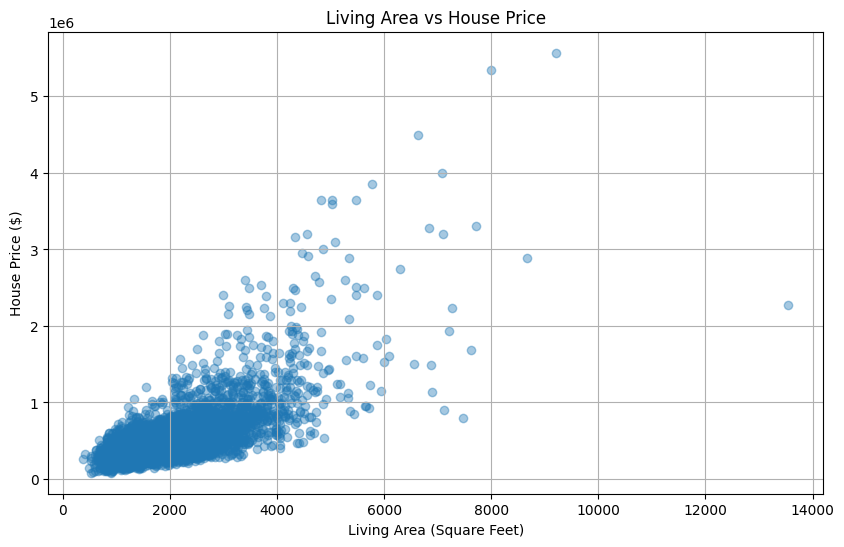

In [16]:
#Creating scatter plot for the Living Area vs House Price
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test["sqft_living"],
    y_test,
    alpha=0.4
)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("House Price ($)")

plt.grid(True)
plt.show()

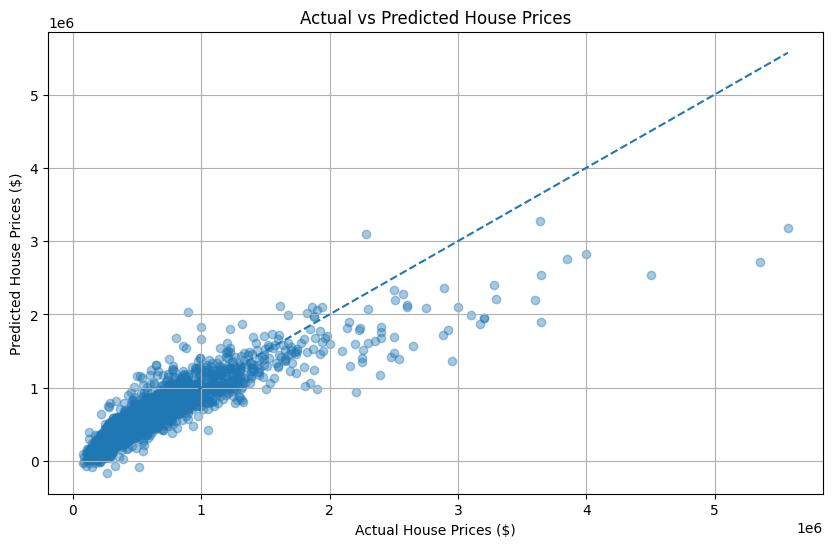

In [17]:
#Scatter plot for predicted house price vs actual house price
plt.figure(figsize=(10, 6))

plt.scatter(y_test, testPredictions, alpha=0.4)

#Reference line for perfect predictions, this is the perfect straight line for referencing
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle="--")

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Prices ($)")
plt.ylabel("Predicted House Prices ($)")

plt.grid(True)
plt.show()

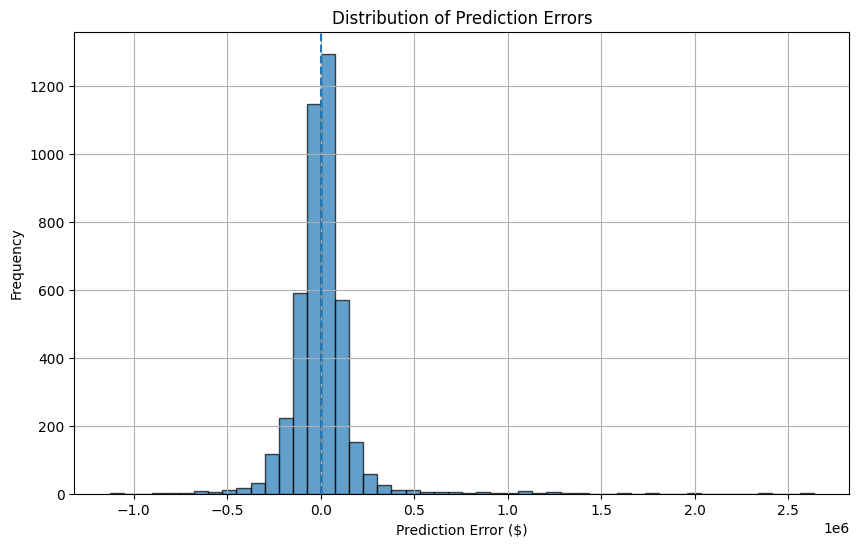

In [18]:
#Calculating the prediction error margin
errors = y_test - testPredictions

#Creating the histogram type visualization
plt.figure(figsize=(10, 6))

plt.hist(errors, bins=50, edgecolor="black", alpha=0.7)

plt.axvline(x=0, linestyle="--")

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error ($)")
plt.ylabel("Frequency")

plt.grid(True)
plt.show()

# Prediction Test

The code below features a prediction using metrics for each feature in the dataset's information. I am going to predict the house price of a FICTIONAL house based on what the dataset has given in the regression algorithm. 

In [19]:
#This is the fictional house's metrics per feature

newHouse = pd.DataFrame({
    "bedrooms": [4],
    "bathrooms": [2.5],#means there's two full bathrooms (shower) and one guest bathroom (no shower)
    "sqft_living": [2500],
    "sqft_lot": [6000],
    "floors": [2],
    "waterfront": [1],#it is a waterfront property
    "view": [0],#no views
    "condition": [4],#based on the dataset, this means the house is in good condition
    "grade": [8],
    "sqft_above": [2000],
    "sqft_basement": [500],
    "yr_built": [1995],
    "yr_renovated": [0],
    "zipcode": [98004],#fictional zipcode
    "lat": [47.62],#these are fictional coordinates
    "long": [-122.20],
    "sqft_living15": [2300],
    "sqft_lot15": [6500]
})

#processing the data into the existing preprocessor
newHouseProcessed = preprocessor.transform(newHouse)

predictedPrice = model.predict(newHouseProcessed)

# Display the prediction
print("House Price Prediction")
print("Predicted Price: ${:,.2f}".format(predictedPrice[0]))


House Price Prediction
Predicted Price: $1,792,202.54


# Written Summary

What proved to be difficult was hunting down the correct dataset that fits the instructions, as well as something simple enough that it can be executed. However, the fact that the King County House Price dataset had this many features like square feet, longitude and latitude, and even the zipcode, made things more difficult. That being said, it didn't exactly violate the needs of the assessment, so I decided to stick with King County. It's worth noting that I used ChatGPT to hunt down this dataset, as it is extremely time consuming to hunt one down by myself. I also used ChatGPT for the feature scaling and categorical encoding parts of this notebook.

The reason I used AI for the two mentioned parts of the code had their reasons. The first is feature scaling, as in the King County dataset, multiple records had varying numbers within the same feature. For example, let's say Record 544 had the ground floor square feet of 40,000 while having 2 bedrooms, to the eyes of the preprocessor, the 40,000 metric greatly overpowers the 2. Feature scaling disables the impact of the larger metric a bit, which if not prevented, would make an extremely big difference in the predicted price of that recorded house. My research, alongside the explanation from ChatGPT, both stated that this preprocessing technique is imperative to prevent the predictions from spiking or decreasing by several digits. 

The other part where I used AI is the utilization of categorical encoding. The only reason I had to use this is because the records of King County had a feature called a zipcode. As King County is in America, each house has their very own zipcode, used by the United States Postal Service and several other delivery services within the country to quickly and efficiently deliver things to said houses. In the eyes of the algorithm, the zipcode is a numerical metric, but does not affect the price of the house in any way. Due to this, I had to separate the zipcode entirely, while not actually deleting it from the dataset when I processed it, by putting it in its own separate category. This is why there is a cell that separates the numerical features from the lone categorical feature. 

Overall, I'd say this was an interesting assessment solely because of the dataset I chose. Some of the information in the dataset, like the zipcode, doesn't reflect with what I learned in class, so I had to AI for those parts and then researched the information to better understand them. I at least ended up with better knowledge about such things, especially about feature scaling, as I can see it being quite the important part of data preprocessing. 